In [1]:
from fenics import Function

from dlra.problem import TestProblemSetup
from dlra.viz import plot_source
from dlra.solvers import (
    DynamicalLowRankCG,
    DirectSolver
)

/home/elias/miniforge3/envs/dlra_env/lib/python3.9/site-packages/ufl/__init__.py:250: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


<Axes: >

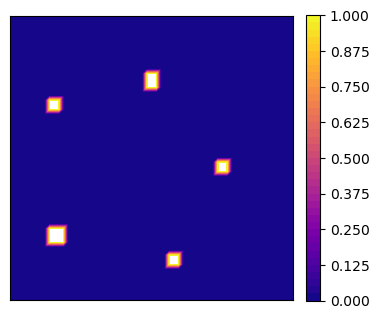

In [2]:
pb = TestProblemSetup(n=64).build(name='V')
plot_source(pb.x, pb.Vh)

In [77]:
pb = TestProblemSetup(n=64).build(name='V')

solver_ds = DirectSolver(
    operator=pb.operator,
    k=50
)

solver_dlra = DynamicalLowRankCG(
    operator=pb.operator,
    k=50,
    x_true=pb.x
)


[##############################] 1000000/1000000


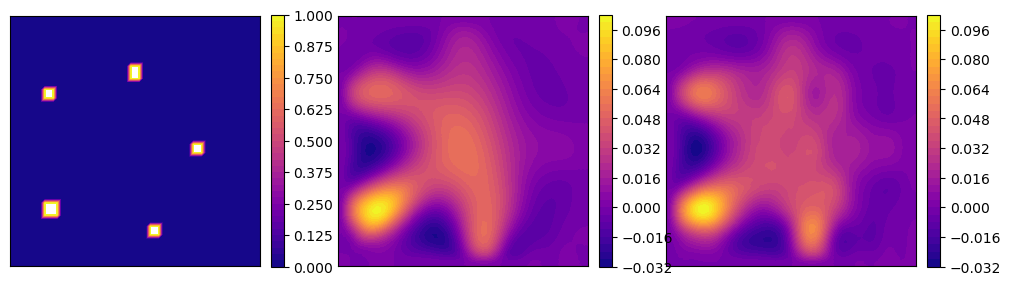

In [95]:
x_ds = solver_ds.solve(
    y=pb.y,
    w=pb.weights,
    lambda_=1e-5
)


x_dlra = solver_dlra.solve(
    y=pb.y,
    w=pb.weights,
    lambda_=1e-5,
    max_rank=5,
    restart_every=20,
    max_iter=1_000_000,
    rtol=0
)

plot_source([pb.x, x_ds, x_dlra], pb.Vh);

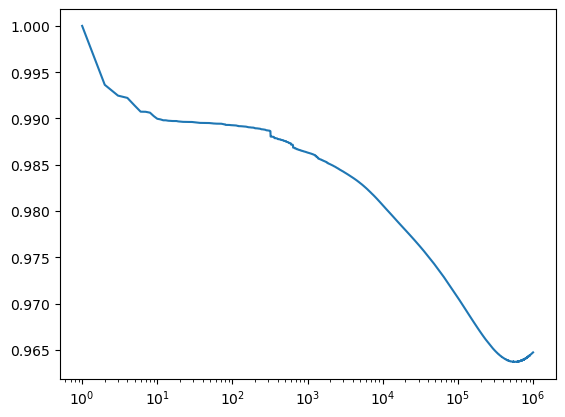

In [96]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(1, len(solver_dlra.error) + 1)
plt.semilogx(x, solver_dlra.error)

[##############################] 1000/1000


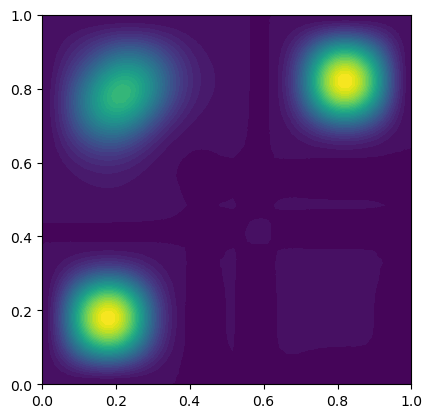

In [9]:
x_hat = solver.solve(
    y=pb.y,
    w=pb.weights,
    lambda_=1e-4,
    max_rank=2,
    restart_every=25,
    max_iter=1000
)

f = Function(pb.Vh)
f.vector()[:] = x_hat
plot(f);